In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.graphics.tsaplots import plot_acf
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
from IPython.display import display

np.random.seed(42)
thread_limit = threadpool_limits(limits=2)
DATA = Path('data')
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
sensors = [f'telemetry_{i}' for i in range(16)]
rare_sensors = sensors[12:]
delay = pd.Timedelta(minutes=15)
gap = pd.Timedelta(minutes=195)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (12, 4),
                     'axes.grid': True, 'grid.alpha': 0.2})

def show():
    plt.tight_layout()
    plt.show()
    plt.close('all')

In [2]:
def read_telemetry(filename):
    df = pd.read_csv(DATA / filename, parse_dates=['datetime'])
    repeats = int(df.datetime.duplicated().sum())
    duplicates = df[df.datetime.duplicated(keep=False)].set_index('datetime')
    conflicts = int((duplicates.groupby(level=0).nunique(dropna=False).max(axis=1) > 1).sum())
    df = df.drop_duplicates().groupby('datetime')[sensors].median().sort_index()
    missing_minutes = len(pd.date_range(df.index.min(), df.index.max(), freq='min')) - len(df)
    df = df.asfreq('min')
    print(filename, ':', len(df), 'минут; повторов времени:', repeats,
          '; конфликтующих минут:', conflicts, '; отсутствующих минут:', missing_minutes)
    return df

def read_target(filename):
    df = pd.read_csv(DATA / filename, parse_dates=['Дата'])
    return df.set_index('Дата')['target'].sort_index()

train = read_telemetry('data_train.csv')
target_train = read_target('target_train.csv')
print('Период телеметрии:', train.index.min(), '—', train.index.max())
print('Число анализов:', len(target_train))
display(train.head())

def longest_constant(s):
    groups = (~(s.eq(s.shift()) & s.notna())).cumsum()
    return s.dropna().groupby(groups[s.notna()]).size().max()

data_info = pd.DataFrame({
    'Пропуски, %': train.isna().mean() * 100,
    'Минимум': train.min(), 'Максимум': train.max(), 'Стандартное отклонение': train.std(),
    'Без изменения, мин': [longest_constant(train[c]) for c in sensors],
    'Интервал записей, мин': [train[c].dropna().index.to_series().diff()
                              .dt.total_seconds().div(60).median() for c in sensors]
})
display(data_info.round(3))

data_train.csv : 317998 минут; повторов времени: 1548 ; конфликтующих минут: 1 ; отсутствующих минут: 0
Период телеметрии: 2019-03-01 00:01:00 — 2019-10-07 19:58:00
Число анализов: 1773


,telemetry_0,telemetry_1,telemetry_2,telemetry_3,telemetry_4,telemetry_5,telemetry_6,telemetry_7,telemetry_8,telemetry_9,telemetry_10,telemetry_11,telemetry_12,telemetry_13,telemetry_14,telemetry_15
datetime,,,,,,,,,,,,,,,,
2019-03-01 00:01:00,0.737538,0.478367,0.292816,0.644016,0.919471,0.884814,0.754800,0.413295,0.47192,0.677801,0.687535,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:02:00,0.738406,0.478977,0.292816,0.648557,0.919471,0.887129,0.752977,0.413295,0.47192,0.677801,0.688926,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:03:00,0.738985,0.478977,0.292816,0.647164,0.919471,0.887129,0.755444,0.413295,0.47192,0.677801,0.690316,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:04:00,0.739563,0.478977,0.292816,0.636938,0.919471,0.887129,0.754800,0.413295,0.47192,0.678079,0.692820,0.498407,NaN,NaN,NaN,NaN
2019-03-01 00:05:00,0.740431,0.477119,0.292816,0.635834,0.919471,0.887707,0.754156,0.413295,0.47192,0.678357,0.695601,0.498407,NaN,NaN,NaN,NaN


,"Пропуски, %",Минимум,Максимум,Стандартное отклонение,"Без изменения, мин","Интервал записей, мин"
telemetry_0,0.005,0.003,1.000,0.276,393,1.0
telemetry_1,0.005,0.000,0.611,0.198,24227,1.0
telemetry_2,0.005,0.032,1.000,0.088,161,1.0
telemetry_3,0.005,0.000,1.000,0.259,24156,1.0
telemetry_4,0.042,0.000,1.000,0.326,38351,1.0
telemetry_5,0.005,0.000,1.000,0.284,274,1.0
telemetry_6,0.005,0.000,1.000,0.300,15522,1.0
telemetry_7,0.005,0.021,1.000,0.253,4328,1.0
telemetry_8,0.005,0.344,1.000,0.024,1427,1.0
telemetry_9,0.005,0.000,1.000,0.255,22180,1.0


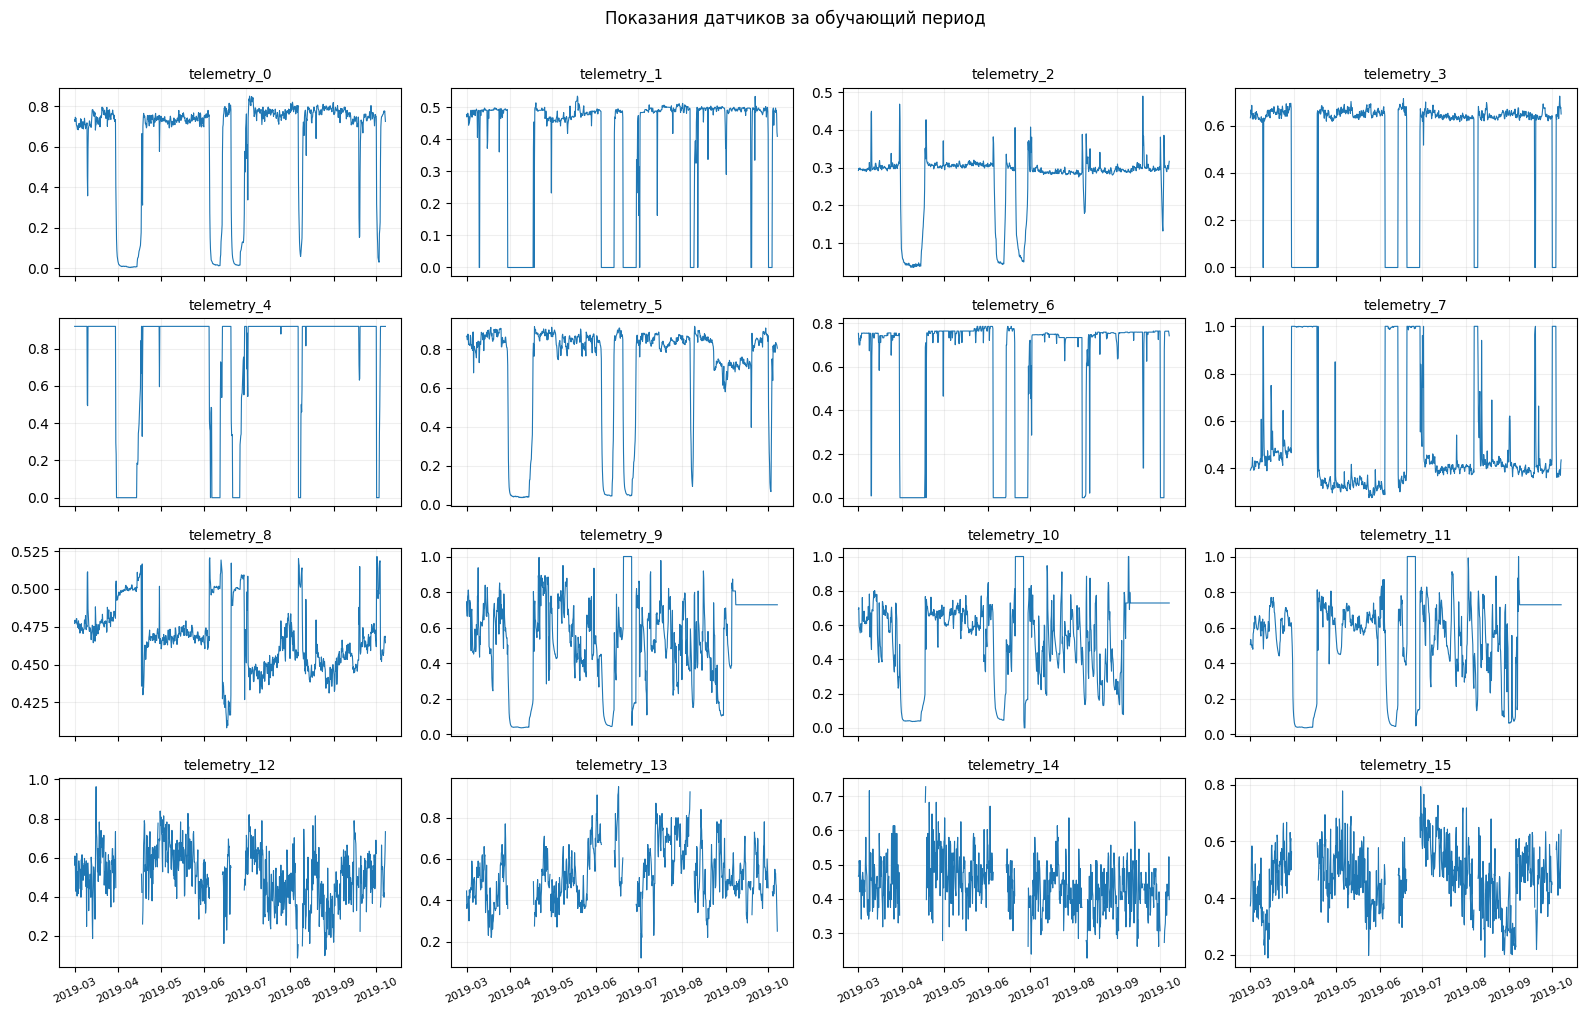

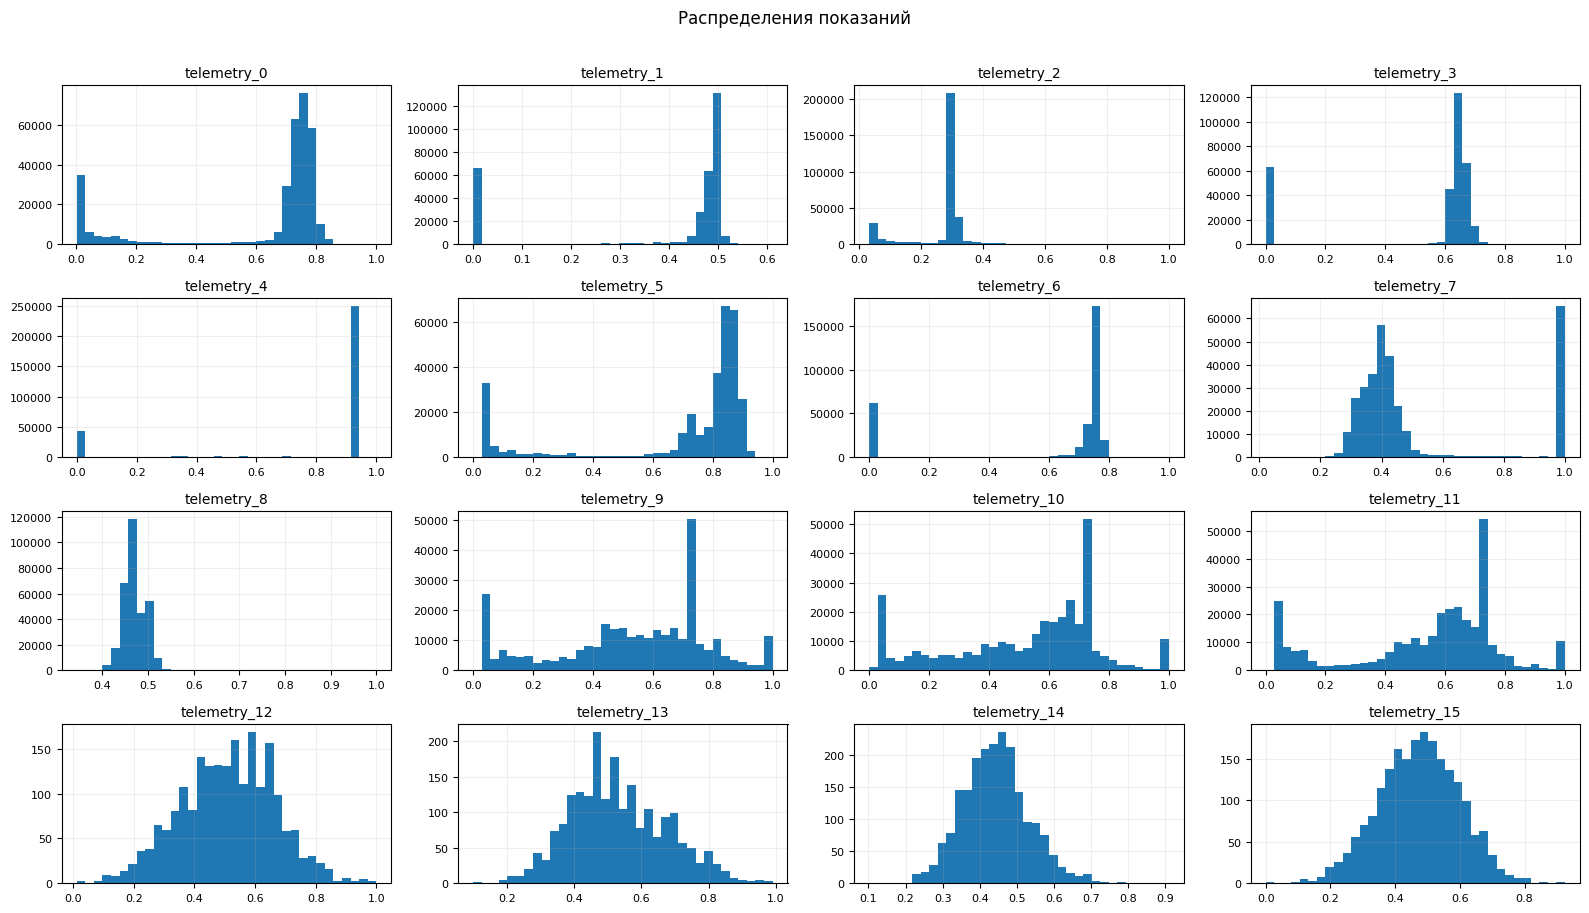

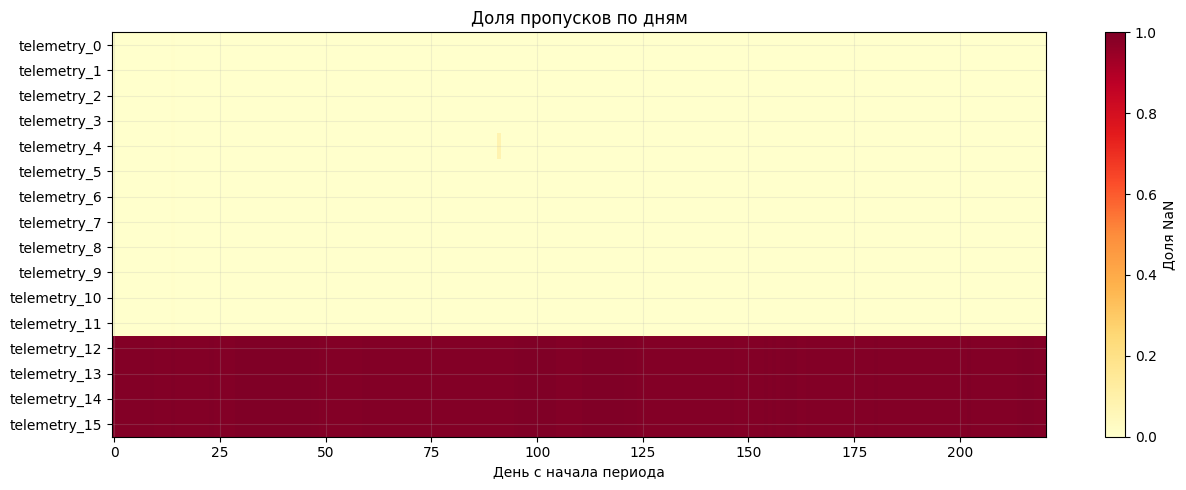

In [3]:
overview = train.resample('6h').median()
fig, axes = plt.subplots(4, 4, figsize=(16, 10), sharex=True)
for ax, col in zip(axes.flat, sensors):
    ax.plot(overview.index, overview[col], linewidth=0.8)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis='x', rotation=25, labelsize=8)
fig.suptitle('Показания датчиков за обучающий период', y=1.01)
show()

fig, axes = plt.subplots(4, 4, figsize=(16, 9))
for ax, col in zip(axes.flat, sensors):
    ax.hist(train[col].dropna(), bins=35)
    ax.set_title(col, fontsize=10)
    ax.tick_params(labelsize=8)
fig.suptitle('Распределения показаний', y=1.01)
show()

plt.figure(figsize=(13, 5))
plt.imshow(train.isna().resample('D').mean().T, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
plt.yticks(range(16), sensors)
plt.xlabel('День с начала периода')
plt.title('Доля пропусков по дням')
plt.colorbar(label='Доля NaN')
show()

У каналов telemetry_12–telemetry_15 очень много пропусков, но записи в основном появляются раз в два часа. Поэтому это скорее редкие измерения, а не постоянная поломка всех четырёх датчиков. Также встречаются длинные ровные участки. По этим данным нельзя точно понять, был это постоянный режим работы или зависшее показание.

Резкие и крайние значения пока не удаляю: для печи это может быть важное изменение режима. Без описания датчиков нет оснований считать все такие значения ошибками.

Медианный интервал между анализами: 120.0 мин
Самый большой перерыв: 18.35 суток
Нулевых значений target: 1


,target
count,1773.000000
mean,0.254272
std,0.092208
min,0.000000
25%,0.175258
50%,0.247423
75%,0.314433
max,0.716495


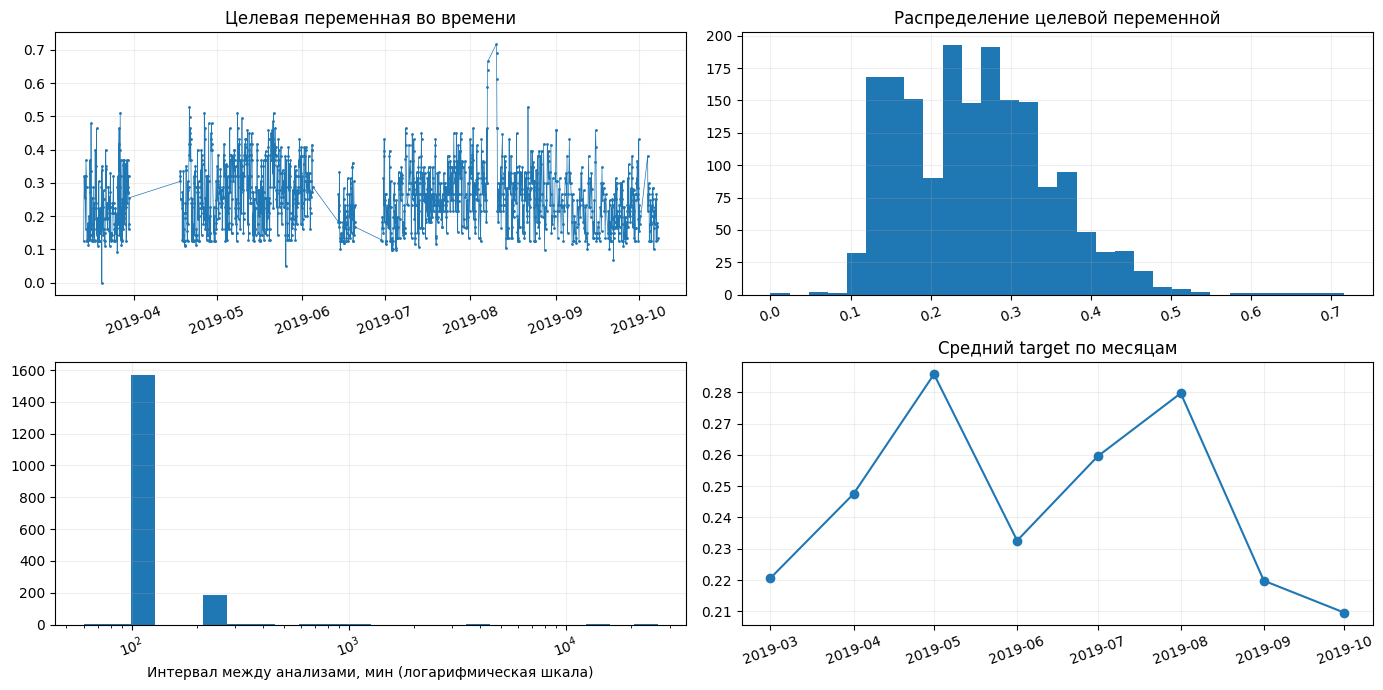

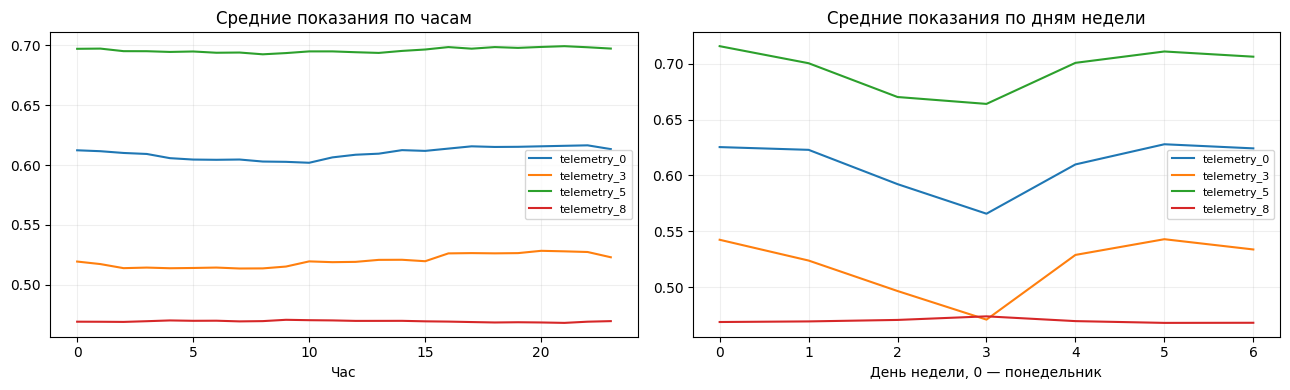

In [4]:
intervals = target_train.index.to_series().diff().dt.total_seconds().div(60).dropna()
display(target_train.describe().to_frame())
print('Медианный интервал между анализами:', intervals.median(), 'мин')
print('Самый большой перерыв:', round(intervals.max() / 1440, 2), 'суток')
print('Нулевых значений target:', target_train.eq(0).sum())

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
axes[0, 0].plot(target_train.index, target_train, '.-', linewidth=0.5, markersize=2)
axes[0, 0].set_title('Целевая переменная во времени')
axes[0, 1].hist(target_train, bins=30)
axes[0, 1].set_title('Распределение целевой переменной')
axes[1, 0].hist(intervals, bins=np.geomspace(intervals.min(), intervals.max()+1, 25))
axes[1, 0].set_xscale('log')
axes[1, 0].set_xlabel('Интервал между анализами, мин (логарифмическая шкала)')
monthly = target_train.resample('MS').mean()
axes[1, 1].plot(monthly.index, monthly, 'o-')
axes[1, 1].set_title('Средний target по месяцам')
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=20)
show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for col in ['telemetry_0', 'telemetry_3', 'telemetry_5', 'telemetry_8']:
    axes[0].plot(train[col].groupby(train.index.hour).mean(), label=col)
    axes[1].plot(train[col].groupby(train.index.dayofweek).mean(), label=col)
axes[0].set(title='Средние показания по часам', xlabel='Час')
axes[1].set(title='Средние показания по дням недели', xlabel='День недели, 0 — понедельник')
for ax in axes:
    ax.legend(fontsize=8)
show()

Анализов за пределами обучающей телеметрии: 1


,0,5,10,15,30,60,120,180
telemetry_0,-0.212,-0.214,-0.216,-0.211,-0.222,-0.208,-0.162,-0.143
telemetry_1,-0.038,-0.042,-0.039,-0.043,-0.036,-0.025,0.003,-0.008
telemetry_2,-0.023,-0.022,-0.019,-0.018,-0.025,-0.030,-0.039,-0.018
telemetry_3,-0.066,-0.054,-0.061,-0.071,-0.099,-0.104,-0.108,-0.093
telemetry_4,-0.009,-0.007,-0.004,-0.006,-0.011,-0.008,-0.007,-0.002
telemetry_5,-0.087,-0.089,-0.091,-0.089,-0.087,-0.099,-0.096,-0.084
telemetry_6,-0.053,-0.052,-0.054,-0.060,-0.064,-0.063,-0.054,-0.063
telemetry_7,-0.112,-0.116,-0.121,-0.118,-0.122,-0.123,-0.131,-0.123
telemetry_8,0.066,0.060,0.053,0.050,0.037,0.041,0.027,0.017
telemetry_9,-0.138,-0.136,-0.137,-0.134,-0.135,-0.131,-0.118,-0.120


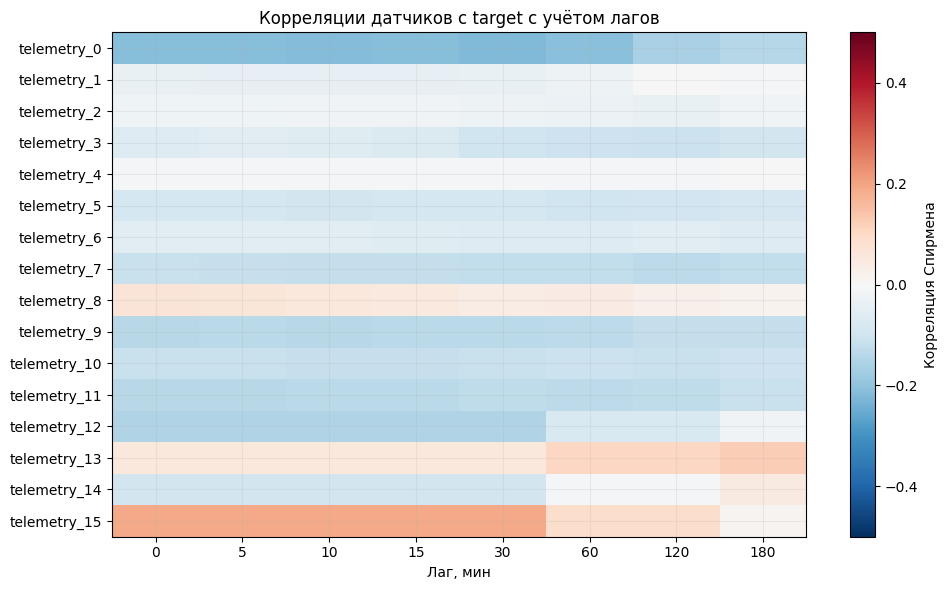

In [5]:
# Считаю target временем отбора; задержка анализа и редких каналов — 15 минут.
def available_values(df):
    values, ages = {}, {}
    times = pd.Series(df.index, index=df.index)
    for col in sensors:
        s = df[col].shift(15 if col in rare_sensors else 0)
        last_time = times.where(s.notna()).ffill()
        age = (times - last_time).dt.total_seconds() / 60
        limit = 240 if col in rare_sensors else 5
        values[col] = s.ffill().where(age <= limit)
        ages[col] = age
    return pd.DataFrame(values), pd.DataFrame(ages)

values, ages = available_values(train)
lab = target_train.loc[target_train.index.isin(train.index)]
print('Анализов за пределами обучающей телеметрии:', len(target_train) - len(lab))

lags = [0, 5, 10, 15, 30, 60, 120, 180]
correlations = pd.DataFrame({lag: values.shift(lag).reindex(lab.index)
                            .corrwith(lab, method='spearman') for lag in lags})
display(correlations.round(3))
plt.figure(figsize=(10, 6))
plt.imshow(correlations, aspect='auto', vmin=-0.5, vmax=0.5, cmap='RdBu_r')
plt.yticks(range(16), sensors)
plt.xticks(range(len(lags)), lags)
plt.xlabel('Лаг, мин')
plt.title('Корреляции датчиков с target с учётом лагов')
plt.colorbar(label='Корреляция Спирмена')
show()

В обучении получилось 317,998 уникальных минут и 1773 лабораторных анализов. Обычно анализы идут через 120 минут, но есть большие перерывы. Один анализ находится за пределами обучающей телеметрии — его исключаю, не подставляя данные из test. Уровень target по месяцам меняется, а суточные профили датчиков в основном довольно ровные. Выраженную устойчивую сезонность по таким графикам утверждать нельзя. Пропуски у редких каналов обрабатываю отдельно. Сильных простых корреляций с target не видно, поэтому одной линейной зависимости может быть недостаточно.

In [6]:
def make_features(df, dates):
    values, ages = available_values(df)
    dates = pd.DatetimeIndex(dates).sort_values().unique()
    features = {}
    times = pd.Series(df.index, index=df.index)

    def add(name, s):
        features[name] = s.reindex(dates).astype('float32')

    for col in sensors:
        s = values[col]
        limit = 240 if col in rare_sensors else 5
        released = df[col].shift(15 if col in rare_sensors else 0)
        changed = released.notna() & released.ne(released.ffill().shift(1))
        last_change = times.where(changed).ffill()
        add(col + '__value', s)
        add(col + '__age', ages[col].clip(upper=10080).fillna(10080))
        add(col + '__stale', ages[col].isna() | (ages[col] > limit))
        add(col + '__missing', released.isna())
        add(col + '__unchanged', ((times-last_change).dt.total_seconds()/60)
            .clip(upper=10080).fillna(10080))
        for lag in [1, 5, 15, 30, 60, 120]:
            add(f'{col}__lag_{lag}', s.shift(lag))
        # Скользящие окна заканчиваются в предыдущую минуту.
        for window in [15, 60, 180]:
            rolling = s.shift(1).rolling(window, min_periods=max(3, window//3))
            for stat in ['mean', 'std', 'min', 'max']:
                add(f'{col}__{stat}_{window}', getattr(rolling, stat)())
        for lag in [5, 15]:
            add(f'{col}__slope_{lag}', (s-s.shift(lag))/lag)
        denominator = s.shift(15).abs().where(s.shift(15).abs() > 1e-6)
        add(col + '__growth_15', (s-s.shift(15))/denominator)

    hour = pd.Series(dates.hour + dates.minute/60, index=dates)
    weekday = pd.Series(dates.dayofweek, index=dates)
    for name, phase, period in [('hour', hour, 24), ('weekday', weekday, 7)]:
        add(f'calendar__{name}_sin', np.sin(2*np.pi*phase/period))
        add(f'calendar__{name}_cos', np.cos(2*np.pi*phase/period))
    return pd.DataFrame(features, index=dates).replace([np.inf, -np.inf], np.nan)

feature_dates = lab.index
for minutes in [10, 12, 15]:
    feature_dates = feature_dates.union(lab.index-pd.Timedelta(minutes=minutes))
feature_dates = feature_dates.intersection(train.index)
features = make_features(train, feature_dates)
X = features.reindex(lab.index)
y = lab.copy()

split_time = X.index[int(len(X)*0.85)]
train_mask = (X.index < split_time-gap) & (X.index+delay <= split_time-gap)
valid_mask = X.index >= split_time
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_valid, y_valid = X.loc[valid_mask], y.loc[valid_mask]
print('Всего признаков:', X.shape[1])
print('Обучение:', X_train.shape, '| Валидация:', X_valid.shape)

Всего признаков: 420
Обучение: (1506, 420) | Валидация: (266, 420)


После добавления лагов признаков становится много. Поэтому для трёх основных моделей удаляю константы и оставляю 64 признака с наибольшей F-статистикой. Заполнение пропусков, отбор и масштабирование обучаются заново внутри каждой обучающей части. PCA не использую: с исходными именами проще понять, какой датчик и какое окно оказались полезны. Корреляция и F-статистика сами по себе не означают причинную связь.

Лаги и средние учитывают, что процесс не меняется мгновенно, а разности помогают описать переходы. Показания из будущего не используются. Возраст и признаки пропусков нужны из-за разных частот регистрации датчиков. Слишком большое число похожих лагов может мешать, поэтому использую отбор.

In [7]:
def model_pipeline(regressor, scale=False):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('variance', VarianceThreshold(1e-12)),
        ('select', SelectKBest(f_regression, k=64)),
        ('scale', StandardScaler() if scale else 'passthrough'),
        ('model', regressor)
    ])

models = {
    'Ridge': model_pipeline(Ridge(alpha=1000), scale=True),
    'ExtraTrees': model_pipeline(ExtraTreesRegressor(
        n_estimators=200, min_samples_leaf=15, max_features=0.8, random_state=42, n_jobs=2)),
    'Бустинг': model_pipeline(HistGradientBoostingRegressor(
        loss='absolute_error', learning_rate=0.05, max_iter=220, max_leaf_nodes=15,
        min_samples_leaf=20, l2_regularization=5, early_stopping=False, random_state=42))
}

def calculate_metrics(y, prediction, dates):
    y, prediction = np.asarray(y), np.asarray(prediction)
    nonzero = np.abs(y) > 1e-6
    dt = np.diff(pd.DatetimeIndex(dates).asi8)/60e9
    dy, dp = np.diff(y), np.diff(prediction)
    pairs = (dt > 0) & (dt <= 360) & (np.abs(dy) > 1e-6)
    return {
        'MAE': mean_absolute_error(y, prediction),
        'RMSE': np.sqrt(mean_squared_error(y, prediction)),
        'MAPE, %': 100*np.mean(np.abs((y[nonzero]-prediction[nonzero])/y[nonzero])),
        'WAPE, %': 100*np.abs(y-prediction).sum()/np.abs(y).sum(),
        'DA, %': 100*np.mean(np.sign(dy[pairs]) == np.sign(dp[pairs])),
        'Delta R2': r2_score(dy[pairs]/dt[pairs], dp[pairs]/dt[pairs]),
        'Точек MAPE': int(nonzero.sum()), 'Переходов DA': int(pairs.sum())
    }

def last_analysis(dates, target, fallback):
    answers = pd.DataFrame({'known_at': target.index+delay, 'value': target.to_numpy()})
    query = pd.DataFrame({'time': dates})
    result = pd.merge_asof(query, answers.sort_values('known_at'),
                          left_on='time', right_on='known_at', direction='backward')
    return result.value.fillna(fallback).to_numpy()

# Зазор 195 минут = максимальное окно + задержка анализа.
start, end = X_train.index.min(), X_train.index.max()+pd.Timedelta(minutes=1)
edges = pd.date_range(start+(end-start)*0.4, end, periods=4)
folds = []
for left, right in zip(edges[:-1], edges[1:]):
    tr = np.flatnonzero((X_train.index < left-gap) & (X_train.index+delay <= left-gap))
    va = np.flatnonzero((X_train.index >= left) & (X_train.index < right))
    folds.append((tr, va))
display(pd.DataFrame([{'Окно': i+1, 'Обучающих точек': len(tr), 'Проверочных точек': len(va),
    'Начало проверки': X_train.index[va].min(), 'Конец проверки': X_train.index[va].max()}
    for i, (tr, va) in enumerate(folds)]))

cv_rows = []
for name, model in models.items():
    for i, (tr, va) in enumerate(folds):
        fitted = clone(model).fit(X_train.iloc[tr], y_train.iloc[tr])
        prediction = fitted.predict(X_train.iloc[va])
        cv_rows.append({'Модель': name, 'Окно': i+1,
                        'MAE': mean_absolute_error(y_train.iloc[va], prediction)})
for i, (tr, va) in enumerate(folds):
    previous = last_analysis(X_train.index[va], target_train, y_train.iloc[tr].median())
    cv_rows.append({'Модель': 'Последний анализ', 'Окно': i+1,
                    'MAE': mean_absolute_error(y_train.iloc[va], previous)})
cv = pd.DataFrame(cv_rows).groupby('Модель').MAE.agg(['mean', 'std'])
display(cv.round(5))
best_name = cv.loc[cv.index.isin(models), 'mean'].idxmin()
print('Лучшая из трёх основных моделей:', best_name)

Лучшая из трёх основных моделей: ExtraTrees


,Окно,Обучающих точек,Проверочных точек,Начало проверки,Конец проверки
0,1,601,230,2019-05-22 21:00:00,2019-06-20 03:00:00
1,2,833,355,2019-06-29 17:00:00,2019-07-31 23:00:00
2,3,1186,318,2019-08-01 01:00:00,2019-09-05 01:00:00


,mean,std
Модель,,
ExtraTrees,0.07166,0.00771
Ridge,0.07198,0.00850
Бустинг,0.07457,0.00993
Последний анализ,0.06249,0.00444


In [8]:
delay_rows = []
for shift in [0, 10, 12, 15]:
    shifted_X = features.reindex(X_train.index-pd.Timedelta(minutes=shift))
    shifted_X.index = X_train.index
    scores = []
    for tr, va in folds:
        fitted = clone(models['Ridge']).fit(shifted_X.iloc[tr], y_train.iloc[tr])
        scores.append(mean_absolute_error(y_train.iloc[va], fitted.predict(shifted_X.iloc[va])))
    delay_rows.append({'Сдвиг назад, мин': shift, 'Средний MAE Ridge': np.mean(scores)})
delay_comparison = pd.DataFrame(delay_rows)
display(delay_comparison.round(5))

fitted_models, timings, valid_predictions = {}, {}, {}
for name, model in models.items():
    t = time.perf_counter()
    fitted_models[name] = clone(model).fit(X_train, y_train)
    timings[name] = time.perf_counter()-t
    valid_predictions[name] = fitted_models[name].predict(X_valid)
valid_scores = pd.DataFrame({name: calculate_metrics(y_valid, p, X_valid.index)
                            for name, p in valid_predictions.items()}).T
display(valid_scores.round(4))

,"Сдвиг назад, мин",Средний MAE Ridge
0,0,0.07198
1,10,0.07166
2,12,0.07160
3,15,0.07164


,MAE,RMSE,"MAPE, %","WAPE, %","DA, %",Delta R2,Точек MAPE,Переходов DA
Ridge,0.0782,0.0946,48.1133,36.4907,56.4516,0.0569,266.0,248.0
ExtraTrees,0.0757,0.0926,46.2158,35.3414,54.4355,0.0277,266.0,248.0
Бустинг,0.0783,0.0956,47.3909,36.5263,56.4516,-0.1277,266.0,248.0


По средней ошибке трёх временных проверок из основных моделей выбрана ExtraTrees, MAE = 0.07166. Последний известный анализ уже на этой проверке даёт меньшую ошибку — 0.06249. Значит, модели пока не показали преимущества по точности уровня. Другой вариант времени анализов немного меняет ошибку, но по одной этой таблице нельзя установить настоящее время отбора пробы. Основное допущение о времени сохраняю. Тестовую часть для выбора модели не использую.

In [9]:
test = read_telemetry('data_test_small.csv')
target_test = read_target('target_test_small.csv')
history = pd.concat([train, test]).asfreq('min')
minute_features = make_features(history, test.index)
X_test = minute_features.reindex(target_test.index)
y_test = target_test.copy()

predictions, prediction_time = {}, {}
for name, model in fitted_models.items():
    t = time.perf_counter()
    predictions[name] = model.predict(X_test)
    prediction_time[name] = time.perf_counter()-t

current_columns = [f'{col}__value' for col in sensors[:12]]
dynamic_columns = current_columns + [f'{col}__mean_60' for col in sensors[:12]] + [
    f'{col}__slope_15' for col in sensors[:12]]
ols_results, information_rows = {}, []
for name, columns in [('OLS без лагов', current_columns), ('OLS с динамикой', dynamic_columns)]:
    t = time.perf_counter()
    prep = Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('scale', StandardScaler())])
    design = sm.add_constant(prep.fit_transform(X_train[columns]), has_constant='add')
    ols = sm.OLS(y_train.to_numpy(), design).fit()
    timings[name] = time.perf_counter()-t
    t = time.perf_counter()
    predictions[name] = ols.predict(sm.add_constant(prep.transform(X_test[columns]), has_constant='add'))
    prediction_time[name] = time.perf_counter()-t
    ols_results[name] = ols
    information_rows.append({'Модель': name, 'AIC': ols.aic, 'BIC': ols.bic,
                             'Число наблюдений': int(ols.nobs)})

all_targets = pd.concat([target_train, target_test]).sort_index()
predictions['Медиана'] = np.full(len(y_test), y_train.median())
predictions['Последний анализ'] = last_analysis(X_test.index, all_targets, y_train.median())
scores = pd.DataFrame({name: calculate_metrics(y_test, p, X_test.index)
                       for name, p in predictions.items()}).T
scores.index.name = 'Модель'
display(scores.round(5).sort_values('MAE'))
scores.to_csv(RESULTS / 'metrics.csv', encoding='utf-8-sig')

information = pd.DataFrame(information_rows).set_index('Модель')
display(information.round(3))
efficiency = pd.DataFrame({'Обучение, с': timings, 'Прогноз 318 точек, с': prediction_time})
display(efficiency.round(4))

data_test_small.csv : 39747 минут; повторов времени: 196 ; конфликтующих минут: 0 ; отсутствующих минут: 0


,MAE,RMSE,"MAPE, %","WAPE, %","DA, %",Delta R2,Точек MAPE,Переходов DA
Модель,,,,,,,,
Последний анализ,0.05949,0.08006,29.71739,28.36825,35.11706,-1.73822,318.0,299.0
OLS с динамикой,0.06793,0.08384,40.01093,32.39318,60.20067,0.03983,318.0,299.0
OLS без лагов,0.06934,0.08459,41.01253,33.06518,56.52174,0.01002,318.0,299.0
ExtraTrees,0.07397,0.08782,44.78290,35.27601,53.51171,-0.05197,318.0,299.0
Ridge,0.07746,0.09039,47.05464,36.93877,57.19064,-0.02068,318.0,299.0
Бустинг,0.08076,0.09538,48.82207,38.50937,50.83612,-0.27407,318.0,299.0
Медиана,0.08218,0.09362,49.82977,39.18992,0.00000,-0.00003,318.0,299.0


,AIC,BIC,Число наблюдений
Модель,,,
OLS без лагов,-3074.123,-3004.999,1506
OLS с динамикой,-3092.922,-2896.185,1506


,"Обучение, с","Прогноз 318 точек, с"
Ridge,0.0329,0.0032
ExtraTrees,0.3103,0.0373
Бустинг,0.4803,0.0074
OLS без лагов,0.0040,0.0013
OLS с динамикой,0.0082,0.0014


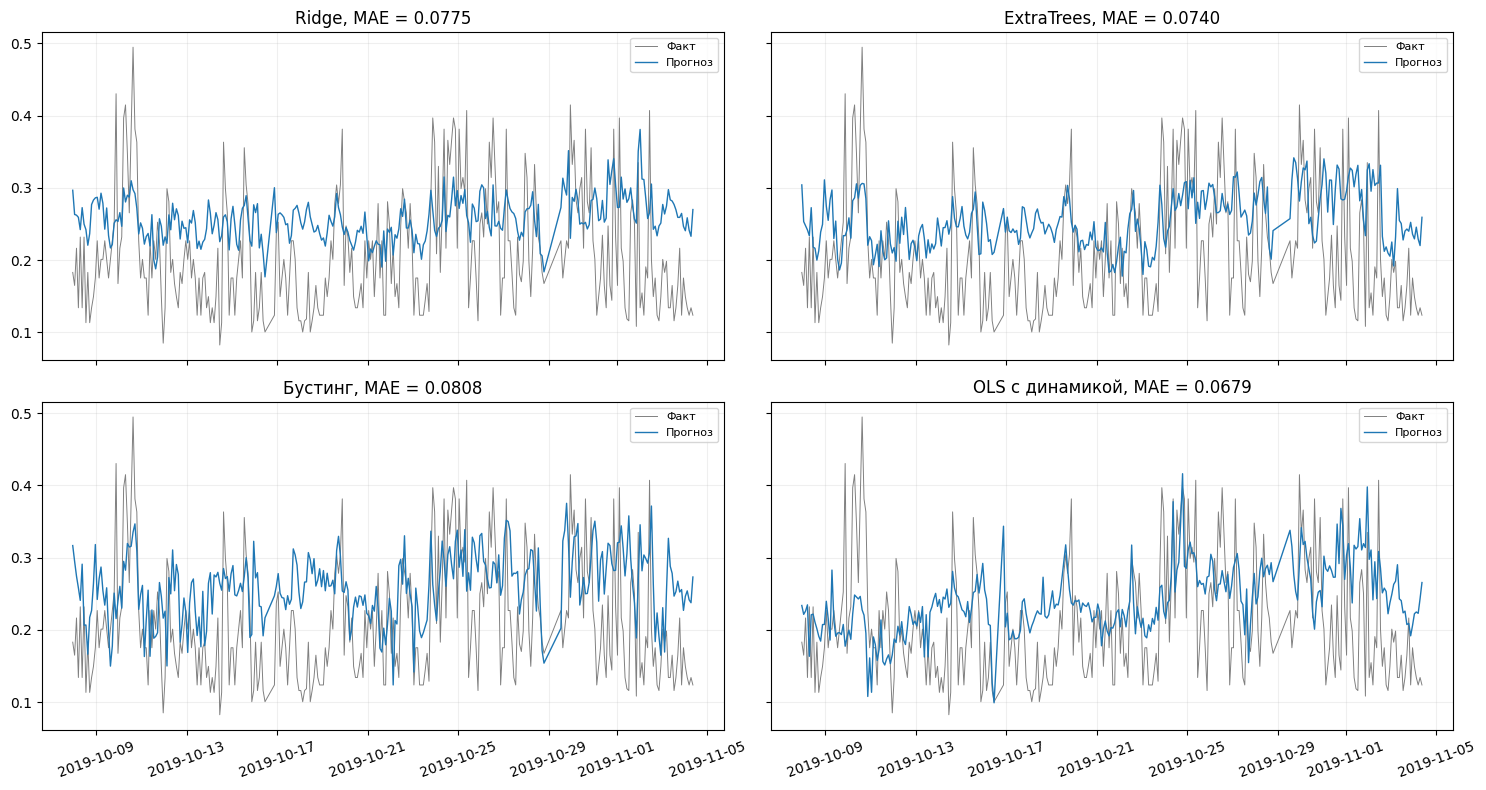

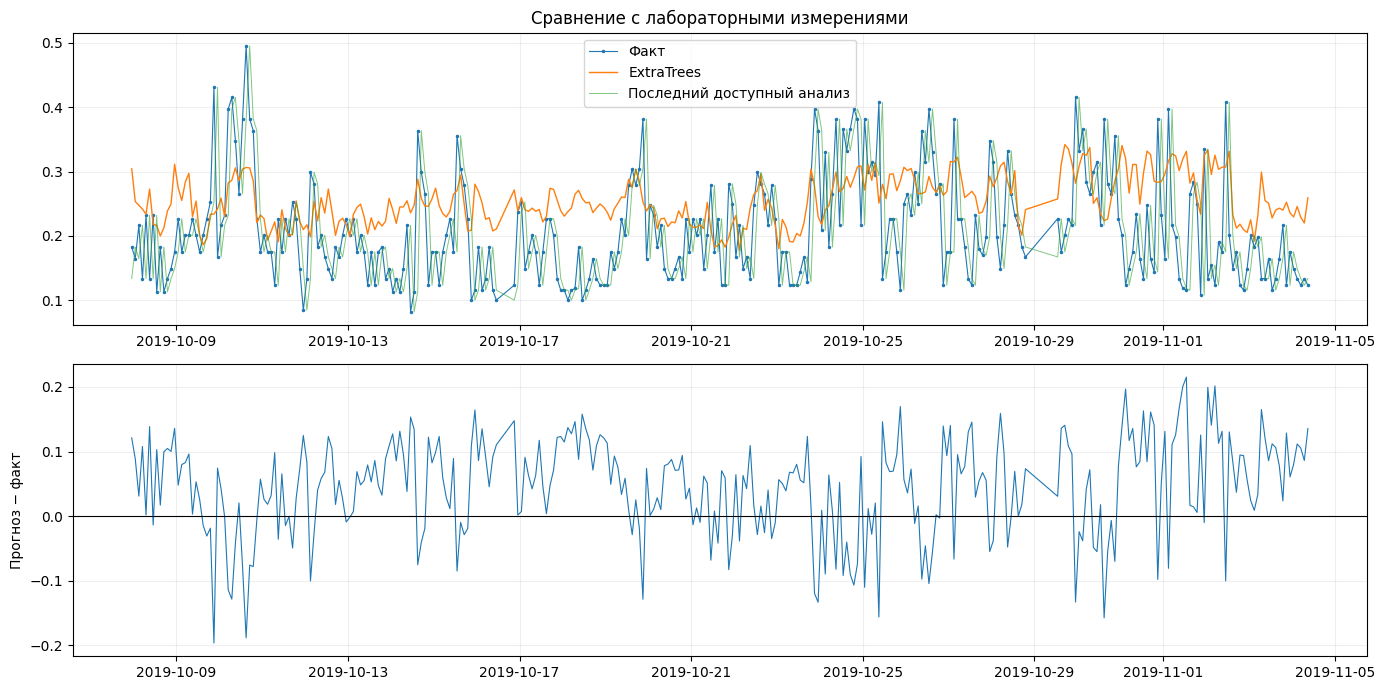

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True, sharey=True)
for ax, name in zip(axes.flat, ['Ridge', 'ExtraTrees', 'Бустинг', 'OLS с динамикой']):
    ax.plot(y_test.index, y_test, color='gray', linewidth=0.7, label='Факт')
    ax.plot(y_test.index, predictions[name], linewidth=1, label='Прогноз')
    ax.set_title(f"{name}, MAE = {scores.loc[name, 'MAE']:.4f}")
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=20)
show()

point = predictions[best_name]
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
axes[0].plot(y_test.index, y_test, '.-', linewidth=0.8, markersize=3, label='Факт')
axes[0].plot(y_test.index, point, label=best_name, linewidth=1)
axes[0].plot(y_test.index, predictions['Последний анализ'], linewidth=0.7,
             alpha=0.6, label='Последний доступный анализ')
axes[0].legend()
axes[0].set_title('Сравнение с лабораторными измерениями')
axes[1].plot(y_test.index, point-y_test.to_numpy(), linewidth=0.8)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_ylabel('Прогноз − факт')
show()

Для автокорреляции: 144 точек, шаг 0 days 02:00:00


,p-value
"Жарк–Бера, p",3.084766e-04
"Льюнг–Бокс, p",3.255531e-12
"Бройш–Паган, p",4.651461e-10


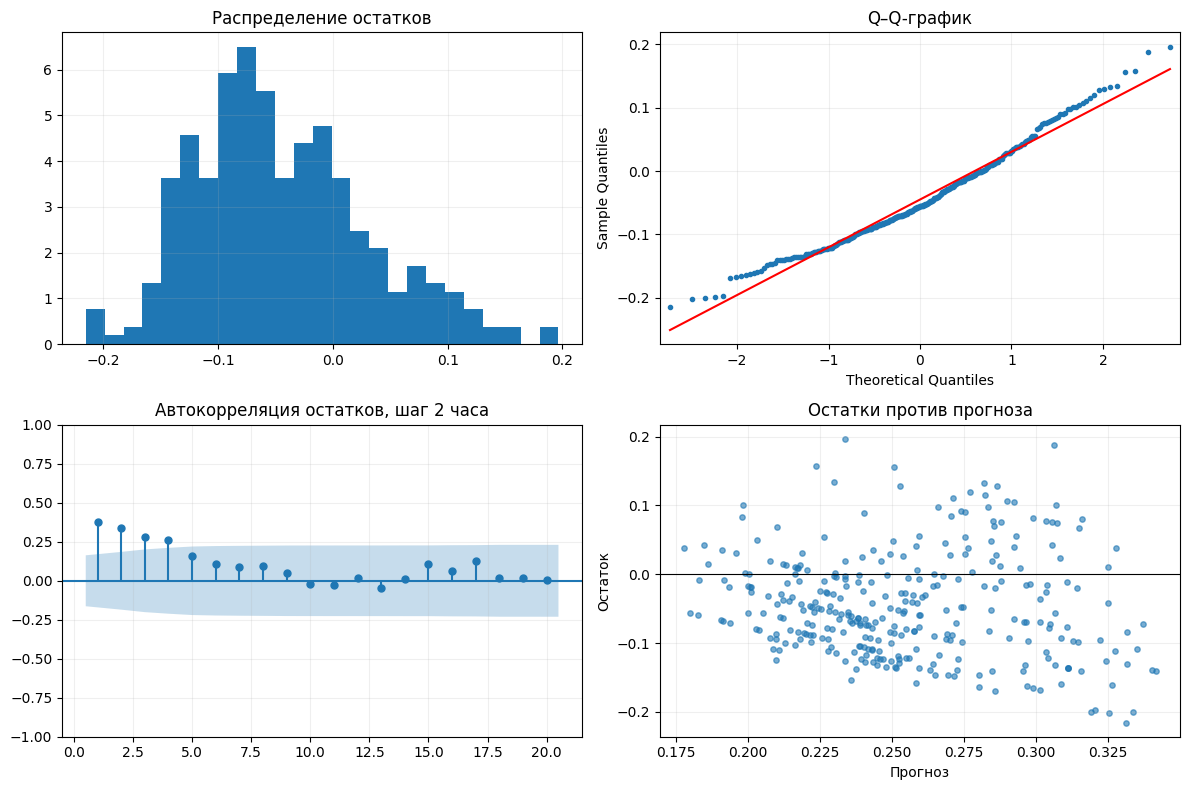

In [11]:
residual = y_test.to_numpy()-point
series = pd.Series(residual, index=y_test.index)
# Для автокорреляции нужен участок без пропусков времени.
step = series.index.to_series().diff().dropna().mode().iloc[0]
regular = series.reindex(pd.date_range(series.index.min(), series.index.max(), freq=step))
groups = regular.notna().ne(regular.notna().shift()).cumsum()
segments = [part for _, part in regular.groupby(groups) if part.notna().all()]
regular_part = max(segments, key=len)

jb = stats.jarque_bera(residual)
lb = acorr_ljungbox(regular_part, lags=[6], return_df=True)
variance_design = sm.add_constant(np.column_stack([point, np.linspace(0, 1, len(point))]))
bp = het_breuschpagan(residual, variance_design, robust=True)
diagnostics = pd.Series({'Жарк–Бера, p': jb.pvalue, 'Льюнг–Бокс, p': lb.lb_pvalue.iloc[0],
                         'Бройш–Паган, p': bp[1]})
display(diagnostics.to_frame('p-value'))
print('Для автокорреляции:', len(regular_part), 'точек, шаг', step)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].hist(residual, bins=25, density=True)
axes[0, 0].set_title('Распределение остатков')
sm.qqplot(residual, line='s', ax=axes[0, 1], markersize=3)
axes[0, 1].set_title('Q–Q-график')
plot_acf(regular_part, lags=20, ax=axes[1, 0], zero=False)
axes[1, 0].set_title('Автокорреляция остатков, шаг 2 часа')
axes[1, 1].scatter(point, residual, s=15, alpha=0.6)
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set(xlabel='Прогноз', ylabel='Остаток', title='Остатки против прогноза')
show()

,Увеличение MAE
telemetry_0__min_15,0.000489
telemetry_12__lag_30,0.000446
telemetry_0__min_60,0.000365
telemetry_0__lag_5,0.000349
telemetry_0__mean_60,0.000316
telemetry_0__lag_30,0.000291
telemetry_6__max_60,0.000276
telemetry_0__value,0.000253
telemetry_0__lag_15,0.000252
telemetry_15__min_60,0.000217


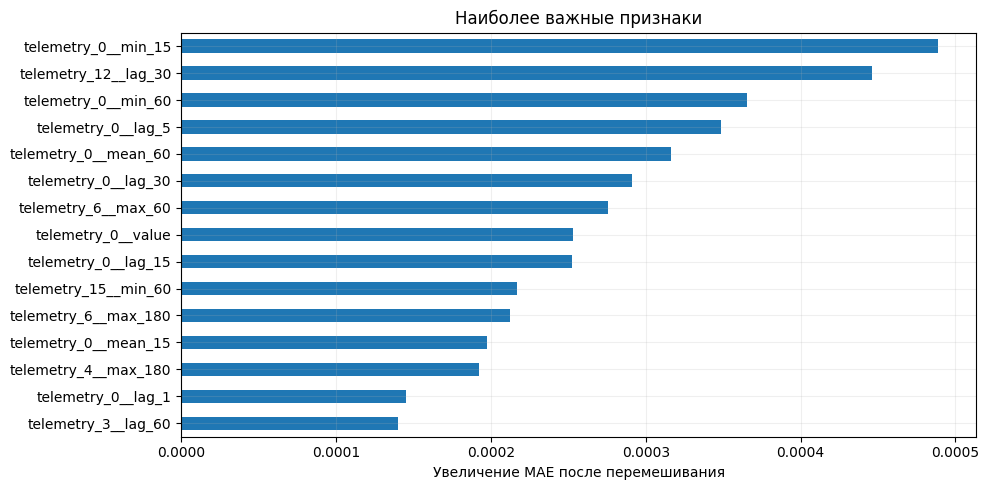

In [12]:
best_model = fitted_models[best_name]
names = best_model[:-1].get_feature_names_out()
transformed = best_model[:-1].transform(X_test)
importance = permutation_importance(best_model[-1], transformed, y_test,
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=42, n_jobs=1)
feature_importance = pd.Series(importance.importances_mean, index=names).sort_values(ascending=False)
display(feature_importance.head(15).to_frame('Увеличение MAE'))
feature_importance.head(15).sort_values().plot.barh(figsize=(10, 5))
plt.xlabel('Увеличение MAE после перемешивания')
plt.title('Наиболее важные признаки')
show()

У модели ExtraTrees на тесте MAE = 0.07397, RMSE = 0.08782, MAPE = 44.78%, WAPE = 35.28%. Направление совпадает в 53.5% ненулевых переходов. Последний известный анализ имеет MAE 0.05949, то есть по ошибке уровня он лучше. У OLS на тесте ошибка тоже меньше, но основная модель с динамикой была выбрана заранее по временной проверке, а не по тесту.

AIC предпочитает OLS с динамикой, BIC — OLS без лагов. BIC сильнее штрафует число параметров. Эти критерии сравниваю только между OLS на одинаковых наблюдениях; у деревьев аналогичный AIC/BIC здесь не рассчитываю. Остатки ненормальны, зависимы во времени и имеют непостоянную дисперсию. Поэтому предпосылки обычной линейной модели выполнены не полностью.

Среди важных признаков есть telemetry_0__min_15, telemetry_12__lag_30, telemetry_0__min_60. Полезность прошлых значений и оконных статистик можно связать с инерцией процесса. Но датчики подписаны номерами, поэтому делать выводы о конкретной температуре или расходе без их описания нельзя.

In [13]:
prediction_table = pd.DataFrame(predictions, index=y_test.index)
prediction_table.insert(0, 'target', y_test)
prediction_table.index.name = 'datetime'
prediction_table.to_csv(RESULTS / 'predictions.csv', encoding='utf-8-sig')

minute_prediction = best_model.predict(minute_features)
pd.DataFrame({'prediction': minute_prediction}, index=minute_features.index).rename_axis(
    'datetime').to_csv(RESULTS / 'minute_predictions.csv')
print('Сохранено минутных прогнозов:', len(minute_prediction))

Сохранено минутных прогнозов: 39747


По точности уровня модель пока уступает последнему доступному лабораторному анализу. Поэтому заменять им лабораторный контроль по этим результатам рано. Полезность для раннего обнаружения изменений нужно проверять отдельно.